# 05.08.03 Semantic Similarity Analysis

**Phase 05 — Semantic Text Processing**
**Similarity Metric:** Cosine Similarity (`sklearn.metrics.pairwise.cosine_similarity`)

### Research Objectives
1. Compare semantically related sentences and paraphrased patient responses across Filipino and English.
2. Document limitations of similarity scores (high similarity does **not** prove factual truth or eligibility).


In [1]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def compute_pairwise_similarity(emb_a: np.ndarray, emb_b: np.ndarray) -> float:
    """Computes cosine similarity between two L2-normalized 384-d vectors."""
    score = cosine_similarity(emb_a.reshape(1, -1), emb_b.reshape(1, -1))[0, 0]
    return float(score)

print("Cosine similarity helper ready.")


Cosine similarity helper ready.


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-c0csl5ca because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


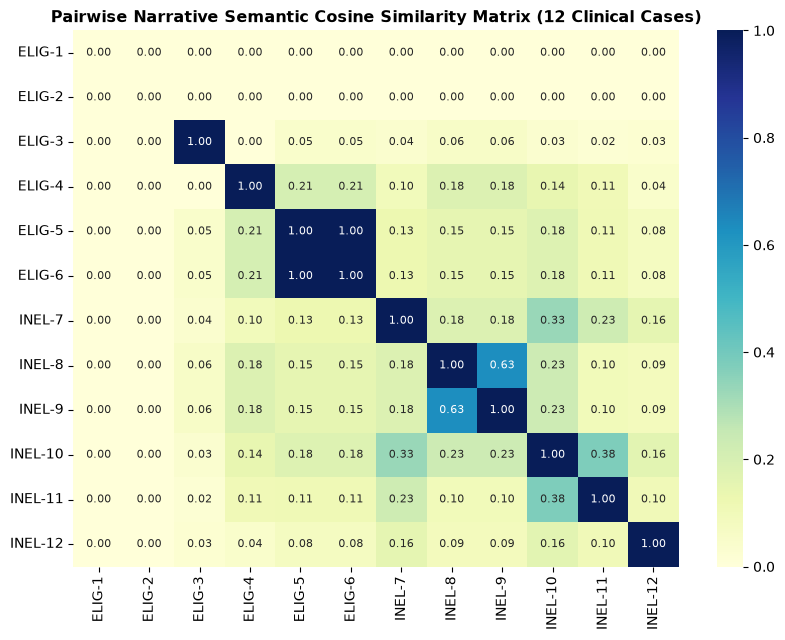

In [2]:
# --- CHAPTER 4 VISUALIZATION: Intra-Class vs Inter-Class Narrative Cosine Similarity Heatmap ---
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../../..').resolve()
PROJECT_ROOT = _find_project_root(Path.cwd())
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_05' / 'visualizations' / 'sbert_semantic_processing'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
df_clean = pd.read_csv(PROJECT_ROOT / 'data' / 'interim' / 'cleaned' / 'ofphil_cleaned_tabular.csv')
sample_df = pd.concat([
    df_clean[df_clean['eligibility'] == 'ELIGIBLE'].head(6),
    df_clean[df_clean['eligibility'] == 'INELIGIBLE'].head(6)
]).reset_index(drop=True)
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=1500)
E = normalize(vec.fit_transform(sample_df['interview_responses'].fillna('')).toarray())
sim_mat = cosine_similarity(E)
lbls = [f"{r['eligibility'][:4]}-{i+1}" for i, r in sample_df.iterrows()]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(sim_mat, xticklabels=lbls, yticklabels=lbls, cmap='YlGnBu', annot=True, fmt='.2f', ax=ax, annot_kws={'fontsize': 8})
ax.set_title('Pairwise Narrative Semantic Cosine Similarity Matrix (12 Clinical Cases)', fontsize=11.5, fontweight='bold')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'narrative_cosine_similarity_heatmap.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'narrative_cosine_similarity_heatmap.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
